# 📊 Feature-by-Feature Visualization Around Thermal Onset ($\tau = 0$)

Using the clean daily dataset (`data/power_grid_simple.csv`), this notebook inspects:
1. The **4-panel benchmark verification figure** — flat pre-onset baseline $\rightarrow$ one clean single surge peak $\rightarrow$ recovery (zero diurnal sawtooth).
2. **What happens around $\tau = 0$ for every dynamic feature** across all `286` events (`Train = 219`, `Test = 67`).
3. A **single-grid multi-feature trace** (`ERCO` Texas January 2024 Arctic Freeze, Test split).
4. A quantitative **before vs. after $\tau = 0$ distribution summary** across all 13 kept dynamic features.

### 1. Load Libraries and the Simple Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the clean, non-redundant daily power grid dataset (one row per event per day)
df = pd.read_csv('data/power_grid_simple.csv')

n_tot = df['sample_id'].nunique()
n_tr = df[df['split'] == 'train']['sample_id'].nunique()
n_te = df[df['split'] == 'test']['sample_id'].nunique()
print(f'Loaded simple dataset: {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Unique events: {n_tot} (Train={n_tr}, Test={n_te}), Unique BAs={df["ba"].nunique()}')
df.head(3)

Loaded simple dataset: 8,294 rows x 24 columns
Unique events: 286 (Train=219, Test=67), Unique BAs=49


,sample_id,ba,region,split,event_type,onset_date,date,tau_day,latitude,longitude,...,solar_share,wind_share,import_share,temp_c,humidity_pct,solar_wm2,wind_ms,pressure_hpa,day_of_week,thermal_discomfort_c
0,0,PACW,NW,train,freeze,2021-01-24,2021-01-10,-14,43.12444,-121.04221,...,0.030929,0.013812,0.453255,-2.564583,88.915000,64.413750,2.140417,847.81665,6,20.564583
1,0,PACW,NW,train,freeze,2021-01-24,2021-01-11,-13,43.12444,-121.04221,...,0.024320,0.108562,0.502673,-1.278750,94.160835,72.301250,2.192917,848.20000,0,19.278750
2,0,PACW,NW,train,freeze,2021-01-24,2021-01-12,-12,43.12444,-121.04221,...,0.006606,0.341187,0.458814,0.590417,95.546250,22.346666,5.217084,843.21670,1,17.409584


### 2. 4-Panel Overview Diagram (Reproducible Code for Benchmark Verification Plot)

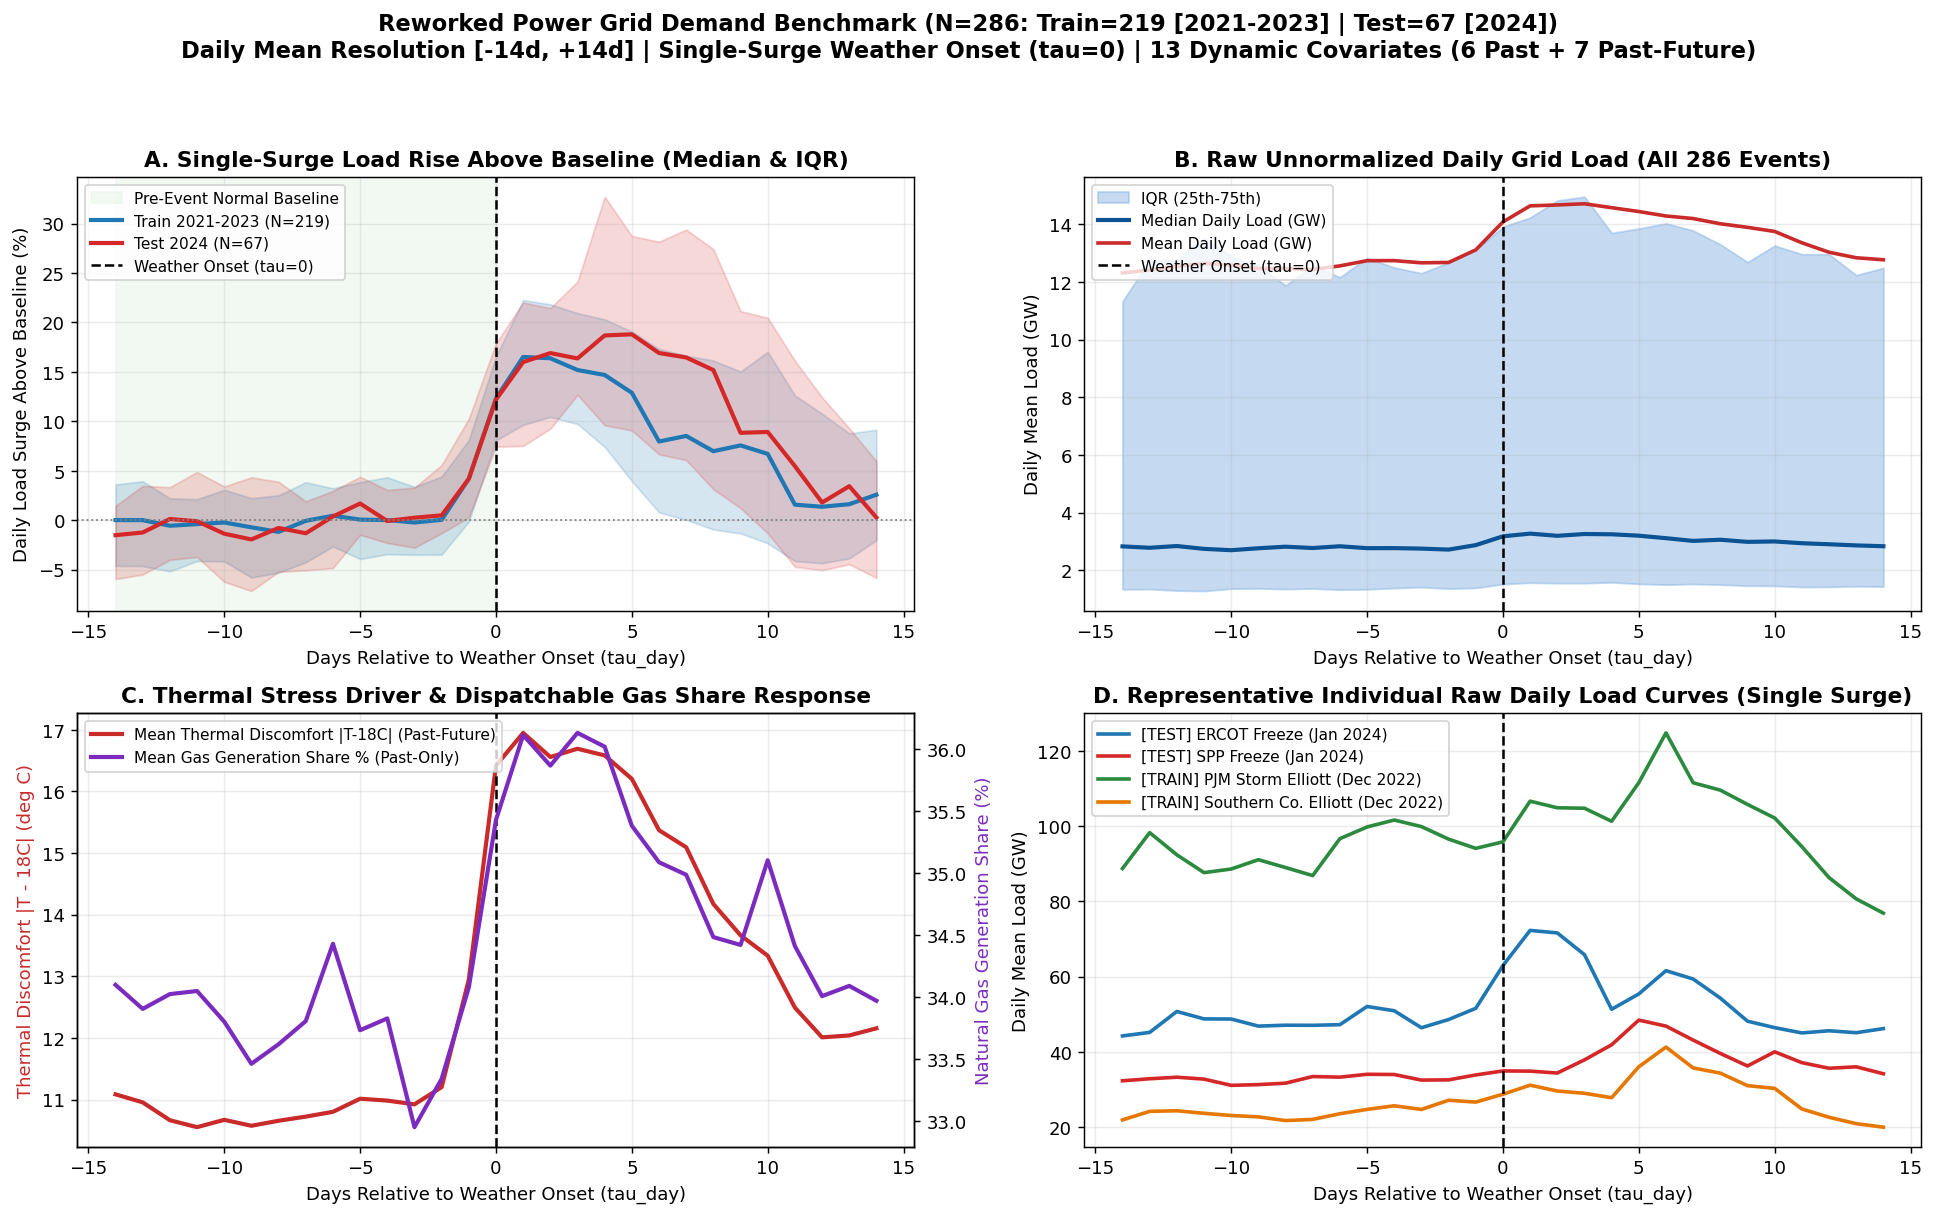

In [2]:
# Compute each event's normal pre-onset median daily load (using tau_day < 0)
pre_med = (
    df[df['tau_day'] < 0]
    .groupby('sample_id')['load_mw']
    .median()
    .rename('pre_med_mw')
)
df = df.merge(pre_med, on='sample_id')
df['surge_pct'] = (df['load_mw'] / df['pre_med_mw'] - 1.0) * 100.0

n_tot = df['sample_id'].nunique()
n_tr = df[df['split'] == 'train']['sample_id'].nunique()
n_te = df[df['split'] == 'test']['sample_id'].nunique()

fig, axes = plt.subplots(2, 2, figsize=(15, 9.5), dpi=130)
fig.suptitle(
    f'Reworked Power Grid Demand Benchmark (N={n_tot}: Train={n_tr} [2021-2023] | Test={n_te} [2024])\n'
    'Daily Mean Resolution [-14d, +14d] | Single-Surge Weather Onset (tau=0) | 13 Dynamic Covariates (6 Past + 7 Past-Future)',
    fontsize=12.5,
    fontweight='bold',
    y=0.98,
)

# --- Panel A: Percent Load Surge Above Baseline (Train vs Test Median & IQR) ---
ax = axes[0, 0]
ax.axvspan(-14, 0, color='#e8f5e9', alpha=0.55, label='Pre-Event Normal Baseline')
for split_name, color, label in [('train', '#1f77b4', f'Train 2021-2023 (N={n_tr})'),
                                 ('test', '#d62728', f'Test 2024 (N={n_te})')]:
    sub = df[df['split'] == split_name]
    g = sub.groupby('tau_day')['surge_pct'].agg(
        med='median',
        q25=lambda s: np.percentile(s, 25),
        q75=lambda s: np.percentile(s, 75),
    ).reset_index()
    ax.plot(g['tau_day'], g['med'], color=color, lw=2.3, label=label)
    ax.fill_between(g['tau_day'], g['q25'], g['q75'], color=color, alpha=0.18)

ax.axvline(0, color='black', ls='--', lw=1.4, label='Weather Onset (tau=0)')
ax.axhline(0, color='gray', ls=':', lw=1.0)
ax.set_title('A. Single-Surge Load Rise Above Baseline (Median & IQR)', fontweight='bold')
ax.set_xlabel('Days Relative to Weather Onset (tau_day)')
ax.set_ylabel('Daily Load Surge Above Baseline (%)')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left', fontsize=8.5)

# --- Panel B: Raw Unnormalized Daily Load Across All Events (GW) ---
ax = axes[0, 1]
raw_stats = (df.groupby('tau_day')['load_mw'].agg(
    med='median',
    mean='mean',
    q25=lambda s: np.percentile(s, 25),
    q75=lambda s: np.percentile(s, 75),
) / 1000.0).reset_index()
ax.fill_between(raw_stats['tau_day'], raw_stats['q25'], raw_stats['q75'], color='#7faee0', alpha=0.45, label='IQR (25th-75th)')
ax.plot(raw_stats['tau_day'], raw_stats['med'], color='#0b5394', lw=2.3, label='Median Daily Load (GW)')
ax.plot(raw_stats['tau_day'], raw_stats['mean'], color='#c92a2a', lw=2.0, label='Mean Daily Load (GW)')
ax.axvline(0, color='black', ls='--', lw=1.4, label='Weather Onset (tau=0)')
ax.set_title(f'B. Raw Unnormalized Daily Grid Load (All {n_tot} Events)', fontweight='bold')
ax.set_xlabel('Days Relative to Weather Onset (tau_day)')
ax.set_ylabel('Daily Mean Load (GW)')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left', fontsize=8.5)

# --- Panel C: Mean Exogenous Thermal Discomfort (Past-Future) & Peaking Gas Share (Past-Only) ---
ax = axes[1, 0]
ax_r = ax.twinx()
grp_f = df.groupby('tau_day')[['thermal_discomfort_c', 'gas_share']].mean().reset_index()
l_td, = ax.plot(grp_f['tau_day'], grp_f['thermal_discomfort_c'], color='#c92a2a', lw=2.3, label='Mean Thermal Discomfort |T-18C| (Past-Future)')
l_gs, = ax_r.plot(grp_f['tau_day'], grp_f['gas_share'] * 100.0, color='#7b2cbf', lw=2.3, label='Mean Gas Generation Share % (Past-Only)')
ax.axvline(0, color='black', ls='--', lw=1.4)
ax.set_title('C. Thermal Stress Driver & Dispatchable Gas Share Response', fontweight='bold')
ax.set_xlabel('Days Relative to Weather Onset (tau_day)')
ax.set_ylabel('Thermal Discomfort |T - 18C| (deg C)', color='#c92a2a')
ax_r.set_ylabel('Natural Gas Generation Share (%)', color='#7b2cbf')
ax.grid(True, alpha=0.25)
ax.legend([l_td, l_gs], [l_td.get_label(), l_gs.get_label()], loc='upper left', fontsize=8.5)

# --- Panel D: Representative Individual Raw Single-Surge Grid Curves ---
ax = axes[1, 1]
for ba, sp, dt_str, col, lbl in [
    ('ERCO', 'test', '2024-01-14', '#1f77b4', '[TEST] ERCOT Freeze (Jan 2024)'),
    ('SWPP', 'test', '2024-01-09', '#d62728', '[TEST] SPP Freeze (Jan 2024)'),
    ('PJM', 'train', '2022-12-18', '#2b8a3e', '[TRAIN] PJM Storm Elliott (Dec 2022)'),
    ('SOCO', 'train', '2022-12-18', '#e67700', '[TRAIN] Southern Co. Elliott (Dec 2022)'),
]:
    m = df[(df['ba'] == ba) & (df['split'] == sp) & (df['onset_date'] == dt_str)]
    if m.empty:
        m = df[(df['ba'] == ba) & (df['split'] == sp)]
    if not m.empty:
        sid = m['sample_id'].iloc[0]
        sub = df[df['sample_id'] == sid].sort_values('tau_day')
        ax.plot(sub['tau_day'], sub['load_mw'] / 1000.0, color=col, lw=2.0, label=lbl)

ax.axvline(0, color='black', ls='--', lw=1.4)
ax.set_title('D. Representative Individual Raw Daily Load Curves (Single Surge)', fontweight='bold')
ax.set_xlabel('Days Relative to Weather Onset (tau_day)')
ax.set_ylabel('Daily Mean Load (GW)')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left', fontsize=8.5)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('data/power_grid_verification.png', dpi=150, bbox_inches='tight')
plt.show()

### 3. What Happens Around $\tau = 0$ for Every Single Feature

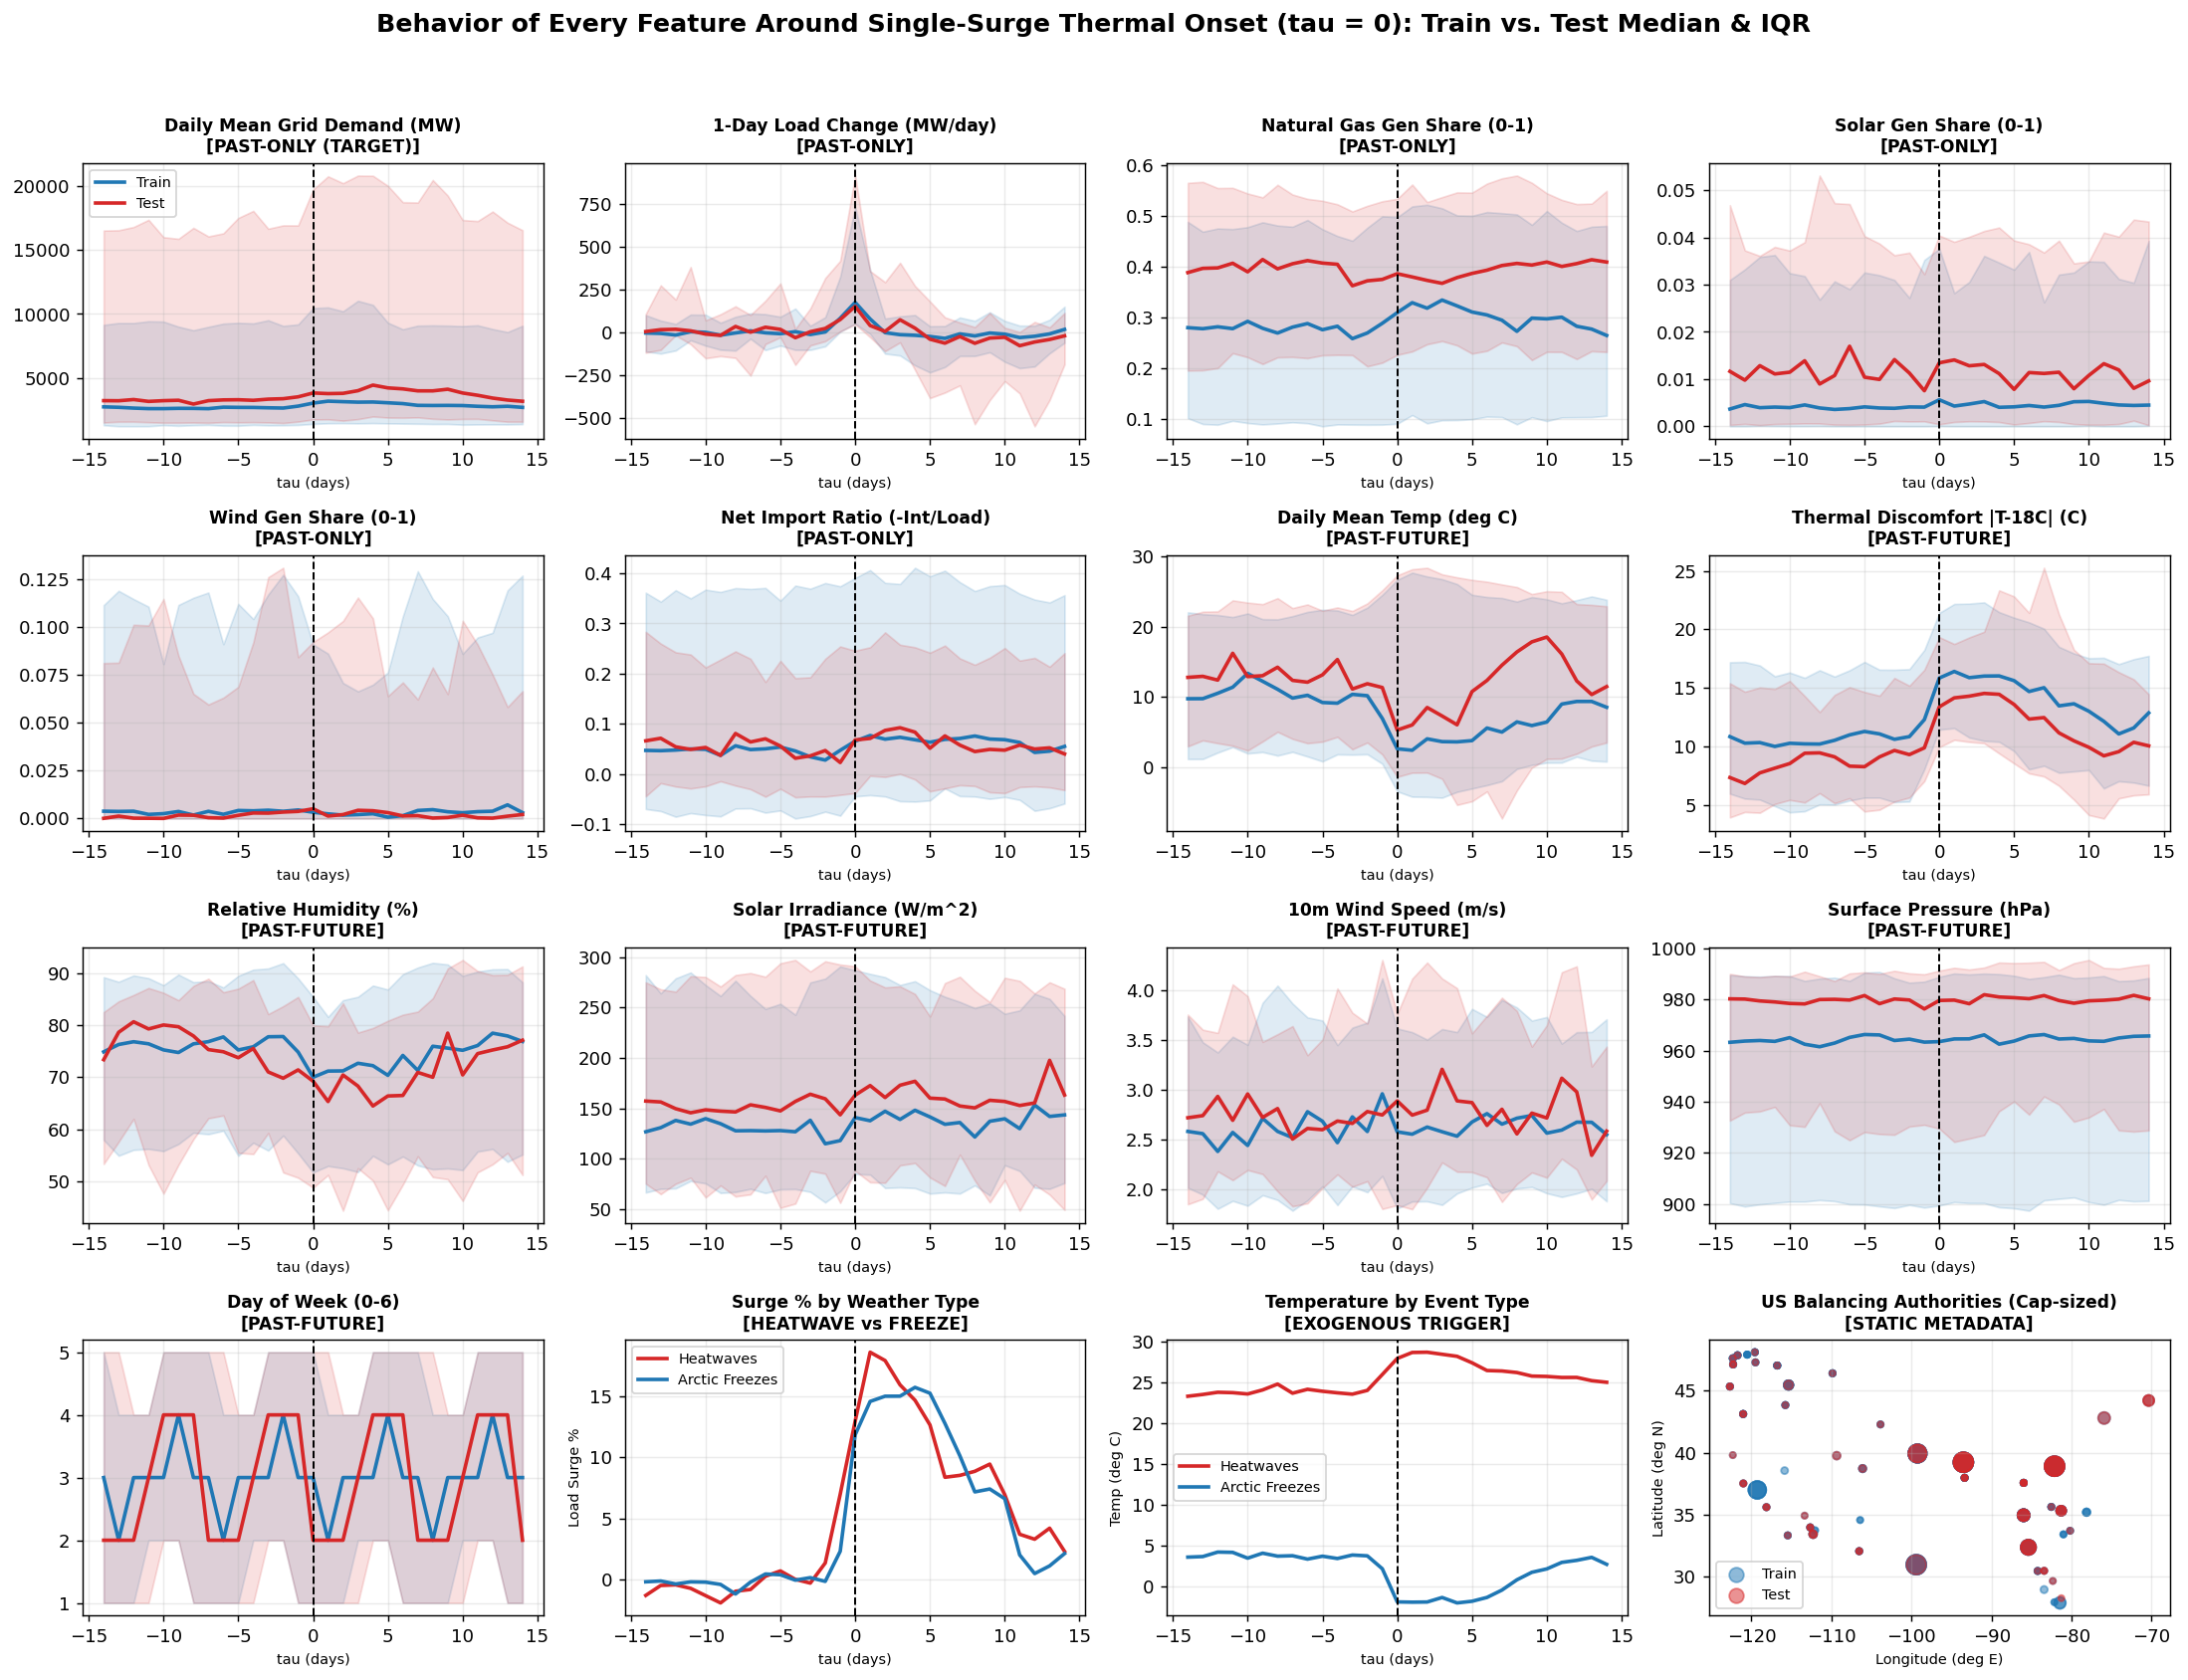

In [3]:
# Human-readable labels & units for all 13 kept dynamic features (6 past-only + 7 past-future)
FEATURES = [
    ('load_mw', 'Daily Mean Grid Demand (MW)', 'PAST-ONLY (TARGET)'),
    ('load_change_1d', '1-Day Load Change (MW/day)', 'PAST-ONLY'),
    ('gas_share', 'Natural Gas Gen Share (0-1)', 'PAST-ONLY'),
    ('solar_share', 'Solar Gen Share (0-1)', 'PAST-ONLY'),
    ('wind_share', 'Wind Gen Share (0-1)', 'PAST-ONLY'),
    ('import_share', 'Net Import Ratio (-Int/Load)', 'PAST-ONLY'),
    ('temp_c', 'Daily Mean Temp (deg C)', 'PAST-FUTURE'),
    ('thermal_discomfort_c', 'Thermal Discomfort |T-18C| (C)', 'PAST-FUTURE'),
    ('humidity_pct', 'Relative Humidity (%)', 'PAST-FUTURE'),
    ('solar_wm2', 'Solar Irradiance (W/m^2)', 'PAST-FUTURE'),
    ('wind_ms', '10m Wind Speed (m/s)', 'PAST-FUTURE'),
    ('pressure_hpa', 'Surface Pressure (hPa)', 'PAST-FUTURE'),
    ('day_of_week', 'Day of Week (0-6)', 'PAST-FUTURE'),
]

fig, axes = plt.subplots(4, 4, figsize=(17, 13), dpi=130)
axes = axes.flatten()

for idx, (col, label, role) in enumerate(FEATURES):
    ax = axes[idx]
    for split_name, color, name in [('train', '#1f77b4', 'Train'), ('test', '#d62728', 'Test')]:
        sub = df[df['split'] == split_name]
        g = sub.groupby('tau_day')[col].agg(
            med='median',
            q25=lambda s: np.percentile(s, 25),
            q75=lambda s: np.percentile(s, 75),
        ).reset_index()
        ax.plot(g['tau_day'], g['med'], color=color, lw=2.0, label=name)
        ax.fill_between(g['tau_day'], g['q25'], g['q75'], color=color, alpha=0.14)

    ax.axvline(0, color='black', ls='--', lw=1.1)
    ax.set_title(f'{label}\n[{role}]', fontsize=9.5, fontweight='bold')
    ax.set_xlabel('tau (days)', fontsize=8)
    ax.grid(True, alpha=0.25)
    if idx == 0:
        ax.legend(loc='upper left', fontsize=8)

# Remaining 3 grid slots: Event type load surge, Event type temperature, US BA geographic map
ax_s1 = axes[13]
for etype, color, lbl in [('heatwave', '#d62728', 'Heatwaves'), ('freeze', '#1f77b4', 'Arctic Freezes')]:
    sub = df[df['event_type'] == etype]
    g = sub.groupby('tau_day')['surge_pct'].median()
    ax_s1.plot(g.index, g.values, color=color, lw=2.0, label=lbl)
ax_s1.axvline(0, color='black', ls='--', lw=1.1)
ax_s1.set_title('Surge % by Weather Type\n[HEATWAVE vs FREEZE]', fontsize=9.5, fontweight='bold')
ax_s1.set_xlabel('tau (days)', fontsize=8)
ax_s1.set_ylabel('Load Surge %', fontsize=8)
ax_s1.grid(True, alpha=0.25)
ax_s1.legend(loc='upper left', fontsize=8)

ax_s2 = axes[14]
for etype, color, lbl in [('heatwave', '#d62728', 'Heatwaves'), ('freeze', '#1f77b4', 'Arctic Freezes')]:
    sub = df[df['event_type'] == etype]
    g = sub.groupby('tau_day')['temp_c'].median()
    ax_s2.plot(g.index, g.values, color=color, lw=2.0, label=lbl)
ax_s2.axvline(0, color='black', ls='--', lw=1.1)
ax_s2.set_title('Temperature by Event Type\n[EXOGENOUS TRIGGER]', fontsize=9.5, fontweight='bold')
ax_s2.set_xlabel('tau (days)', fontsize=8)
ax_s2.set_ylabel('Temp (deg C)', fontsize=8)
ax_s2.grid(True, alpha=0.25)
ax_s2.legend(loc='center left', fontsize=8)

ax_s3 = axes[15]
meta_u = df.drop_duplicates('sample_id')
for split_name, color, name in [('train', '#1f77b4', 'Train'), ('test', '#d62728', 'Test')]:
    sub = meta_u[meta_u['split'] == split_name]
    ax_s3.scatter(sub['longitude'], sub['latitude'], s=np.clip(sub['installed_cap_mw'] / 1000.0, 12, 120), alpha=0.5, color=color, label=name)
ax_s3.set_title('US Balancing Authorities (Cap-sized)\n[STATIC METADATA]', fontsize=9.5, fontweight='bold')
ax_s3.set_xlabel('Longitude (deg E)', fontsize=8)
ax_s3.set_ylabel('Latitude (deg N)', fontsize=8)
ax_s3.grid(True, alpha=0.25)
ax_s3.legend(loc='lower left', fontsize=8)

plt.suptitle(
    'Behavior of Every Feature Around Single-Surge Thermal Onset (tau = 0): Train vs. Test Median & IQR',
    fontsize=14,
    fontweight='bold',
    y=0.995,
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('data/power_grid_all_features_around_surge.png', dpi=150, bbox_inches='tight')
plt.show()

### 4. Detailed Single-Grid Walkthrough Across Key Features

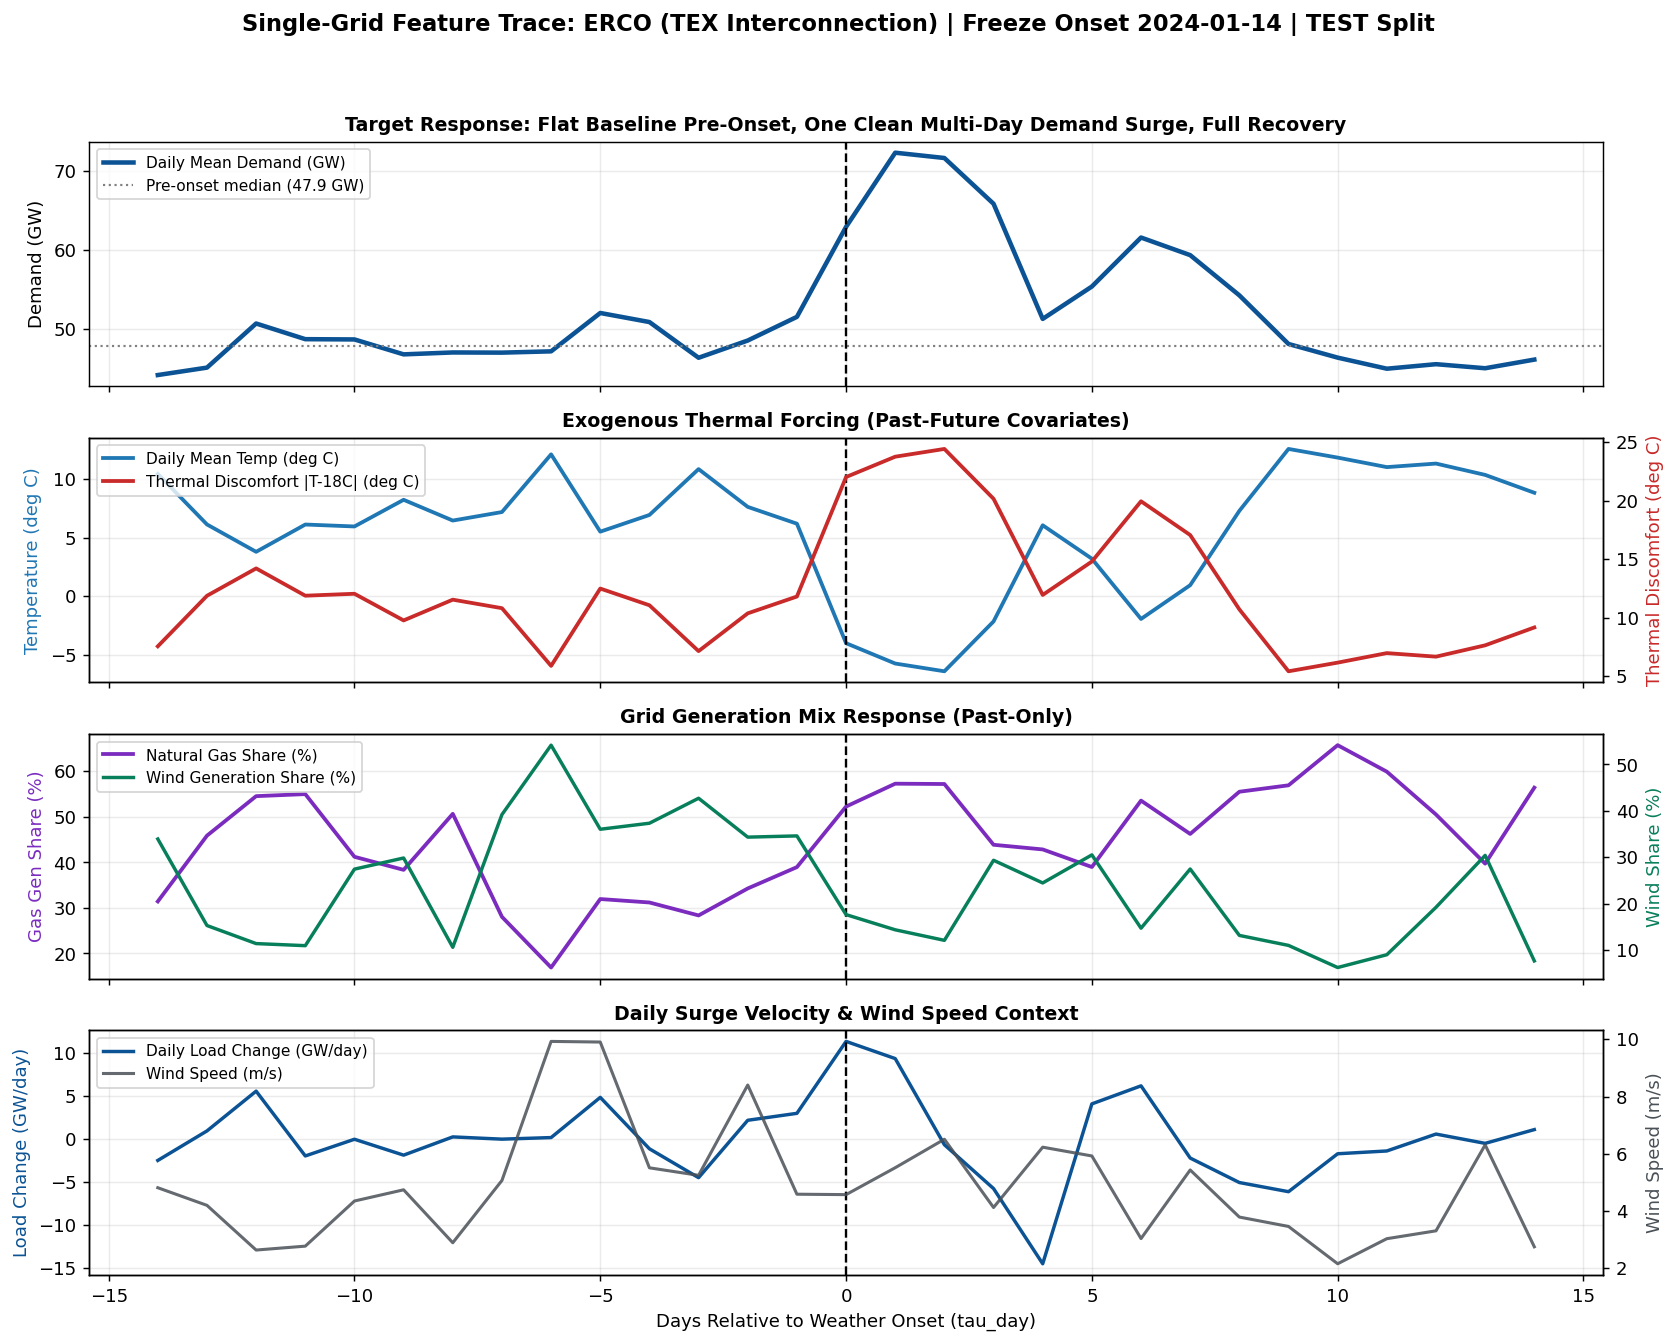

In [4]:
# Pick one dramatic Test-split single surge: ERCO Texas January 2024 Freeze
erco_rows = df[(df['ba'] == 'ERCO') & (df['split'] == 'test')]
sid = erco_rows['sample_id'].iloc[0]
sample = df[df['sample_id'] == sid].sort_values('tau_day')
meta_r = sample.iloc[0]

fig, axes = plt.subplots(4, 1, figsize=(13, 10.5), dpi=130, sharex=True)
fig.suptitle(
    f'Single-Grid Feature Trace: {meta_r["ba"]} ({meta_r["region"]} Interconnection) | '
    f'{meta_r["event_type"].title()} Onset {meta_r["onset_date"]} | {meta_r["split"].upper()} Split',
    fontsize=12.5,
    fontweight='bold',
    y=0.98,
)

# 1. Target electricity load (clean single surge!)
axes[0].plot(sample['tau_day'], sample['load_mw'] / 1000.0, color='#0b5394', lw=2.5, label='Daily Mean Demand (GW)')
axes[0].axhline(meta_r['pre_med_mw'] / 1000.0, color='gray', ls=':', lw=1.2, label=f'Pre-onset median ({meta_r["pre_med_mw"]/1000:.1f} GW)')
axes[0].set_ylabel('Demand (GW)')
axes[0].set_title('Target Response: Flat Baseline Pre-Onset, One Clean Multi-Day Demand Surge, Full Recovery', fontweight='bold', fontsize=10.5)
axes[0].legend(loc='upper left', fontsize=8.5)

# 2. Exogenous temperature plunge & thermal discomfort (Past-Future)
ax1_r = axes[1].twinx()
l_t, = axes[1].plot(sample['tau_day'], sample['temp_c'], color='#1f77b4', lw=2.1, label='Daily Mean Temp (deg C)')
l_td, = ax1_r.plot(sample['tau_day'], sample['thermal_discomfort_c'], color='#c92a2a', lw=2.1, label='Thermal Discomfort |T-18C| (deg C)')
axes[1].set_ylabel('Temperature (deg C)', color='#1f77b4')
ax1_r.set_ylabel('Thermal Discomfort (deg C)', color='#c92a2a')
axes[1].set_title('Exogenous Thermal Forcing (Past-Future Covariates)', fontweight='bold', fontsize=10.5)
axes[1].legend([l_t, l_td], [l_t.get_label(), l_td.get_label()], loc='upper left', fontsize=8.5)

# 3. Dispatchable gas share & net imports (Past-Only)
ax2_r = axes[2].twinx()
l_g, = axes[2].plot(sample['tau_day'], sample['gas_share'] * 100.0, color='#7b2cbf', lw=2.1, label='Natural Gas Share (%)')
l_w, = ax2_r.plot(sample['tau_day'], sample['wind_share'] * 100.0, color='#087f5b', lw=1.9, label='Wind Generation Share (%)')
axes[2].set_ylabel('Gas Gen Share (%)', color='#7b2cbf')
ax2_r.set_ylabel('Wind Share (%)', color='#087f5b')
axes[2].set_title('Grid Generation Mix Response (Past-Only)', fontweight='bold', fontsize=10.5)
axes[2].legend([l_g, l_w], [l_g.get_label(), l_w.get_label()], loc='upper left', fontsize=8.5)

# 4. Daily ramp & wind speed
ax3_r = axes[3].twinx()
l_r, = axes[3].plot(sample['tau_day'], sample['load_change_1d'] / 1000.0, color='#0b5394', lw=1.9, label='Daily Load Change (GW/day)')
l_ws, = ax3_r.plot(sample['tau_day'], sample['wind_ms'], color='#495057', lw=1.7, alpha=0.85, label='Wind Speed (m/s)')
axes[3].set_ylabel('Load Change (GW/day)', color='#0b5394')
ax3_r.set_ylabel('Wind Speed (m/s)', color='#495057')
axes[3].set_xlabel('Days Relative to Weather Onset (tau_day)')
axes[3].set_title('Daily Surge Velocity & Wind Speed Context', fontweight='bold', fontsize=10.5)
axes[3].legend([l_r, l_ws], [l_r.get_label(), l_ws.get_label()], loc='upper left', fontsize=8.5)

for a in axes:
    a.axvline(0, color='black', ls='--', lw=1.3)
    a.grid(True, alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('data/power_grid_single_region_features.png', dpi=150, bbox_inches='tight')
plt.show()

### 5. Before vs. After $\tau = 0$: Numerical Comparison Across All Events

In [5]:
before = df[df['tau_day'] < 0]
after = df[df['tau_day'] >= 0]

rows = []
for col, label, role in FEATURES:
    pre_med = before[col].median()
    post_med = after[col].median()
    pre_peak = before.groupby('sample_id')[col].max().median()
    post_peak = after.groupby('sample_id')[col].max().median()
    rows.append({
        'Feature': col,
        'Role': role,
        'Pre-Onset Median': round(pre_med, 2),
        'Post-Onset Median': round(post_med, 2),
        'Pre-Onset Peak Median': round(pre_peak, 2),
        'Post-Onset Peak Median': round(post_peak, 2),
        'Median Shift': round(post_med - pre_med, 2),
    })

summary_tbl = pd.DataFrame(rows)
display(summary_tbl)

,Feature,Role,Pre-Onset Median,Post-Onset Median,Pre-Onset Peak Median,Post-Onset Peak Median,Median Shift
0,load_mw,PAST-ONLY (TARGET),2797.81,3080.21,3070.54,3562.96,282.40
1,load_change_1d,PAST-ONLY,4.25,-2.75,276.38,398.08,-7.00
2,gas_share,PAST-ONLY,0.30,0.32,0.40,0.41,0.02
3,solar_share,PAST-ONLY,0.01,0.01,0.01,0.01,0.00
4,wind_share,PAST-ONLY,0.00,0.00,0.01,0.01,-0.00
5,import_share,PAST-ONLY,0.05,0.06,0.11,0.13,0.02
6,temp_c,PAST-FUTURE,10.96,6.99,17.16,14.22,-3.97
7,thermal_discomfort_c,PAST-FUTURE,10.18,13.68,13.82,18.70,3.51
8,humidity_pct,PAST-FUTURE,76.42,72.91,89.62,89.53,-3.51
9,solar_wm2,PAST-FUTURE,134.85,144.77,168.59,180.22,9.92
